In [1]:
import fastf1 as f1

f1.Cache.enable_cache('fastf1_cache')

In [31]:
import pandas as pd

In [38]:
data = pd.read_csv('all/all_Australian Grand Prix.csv')

In [39]:
print(data.shape)

(5730, 33)


In [40]:
print(data['Driver'])

0       ALO
1       ALO
2       ALO
3       ALO
4       ALO
       ... 
5725    VER
5726    VER
5727    VER
5728    VER
5729    VER
Name: Driver, Length: 5730, dtype: object


In [41]:
print(data.columns)

Index(['Driver', 'Team', 'LapNumber', 'LapTime', 'Position', 'Stint',
       'TyreLife', 'Compound', 'FreshTyre', 'TrackStatus', 'PitInTime',
       'PitOutTime', 'IsAccurate', 'TrackTemp', 'AirTemp', 'Humidity',
       'Rainfall', 'IsInLap', 'IsOutLap', 'IsSC', 'IsVSC', 'Year', 'Circuit',
       'StartingPosition', 'LapTimeDelta', 'LapTime_lag1', 'LapTime_lag2',
       'LapTime_lag3', 'PaceVsMedian', 'HistPaceVsMedian', 'FuelLoad',
       'GroudEffectEra', 'IsRestartLap'],
      dtype='object')


In [23]:
print(data.loc[data['Driver'] == 'ALB', ['PaceVsMedian', 'Year', 'LapNumber']])

     PaceVsMedian  Year  LapNumber
0         -7.4030  2023        1.0
1          0.0000  2023        2.0
2          4.5580  2023        3.0
3         -0.7810  2023        4.0
4         -0.8620  2023        5.0
..            ...   ...        ...
953        0.8550  2024       53.0
954        2.4150  2024       54.0
955        0.6960  2024       55.0
956        2.3410  2024       56.0
957        3.0185  2024       57.0

[63 rows x 3 columns]


In [42]:
print(data['Year'].unique())

[2018 2019 2022 2023 2024 2025]


In [43]:
import matplotlib.pyplot as plt

In [34]:
events_by_name = {}
for year in range(2018, 2026):
    schedule = f1.get_event_schedule(year, include_testing=False)
    for name in schedule['EventName']:
        if name not in events_by_name:
            events_by_name[name] = []
        events_by_name[name].append(year)

for name in events_by_name:
    print(name)

Australian Grand Prix
Bahrain Grand Prix
Chinese Grand Prix
Azerbaijan Grand Prix
Spanish Grand Prix
Monaco Grand Prix
Canadian Grand Prix
French Grand Prix
Austrian Grand Prix
British Grand Prix
German Grand Prix
Hungarian Grand Prix
Belgian Grand Prix
Italian Grand Prix
Singapore Grand Prix
Russian Grand Prix
Japanese Grand Prix
United States Grand Prix
Mexican Grand Prix
Brazilian Grand Prix
Abu Dhabi Grand Prix
Styrian Grand Prix
70th Anniversary Grand Prix
Tuscan Grand Prix
Eifel Grand Prix
Portuguese Grand Prix
Emilia Romagna Grand Prix
Turkish Grand Prix
Sakhir Grand Prix
Dutch Grand Prix
Mexico City Grand Prix
São Paulo Grand Prix
Qatar Grand Prix
Saudi Arabian Grand Prix
Miami Grand Prix
Las Vegas Grand Prix


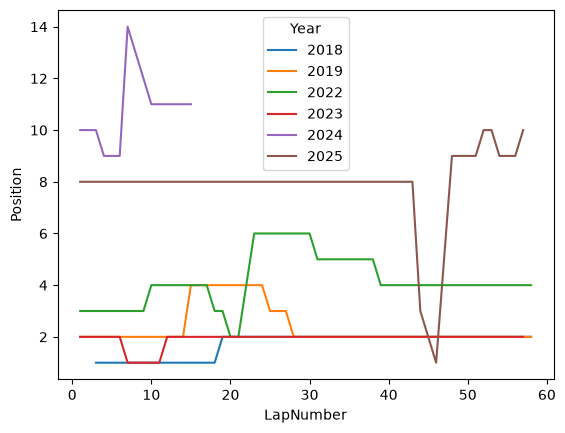

In [44]:
ham = data.loc[data['Driver'] == 'HAM' , ['Position', 'LapNumber' , 'Year']]

for year, group in ham.groupby('Year'):
    plt.plot(group['LapNumber'], group['Position'], label = year)

plt.xlabel('LapNumber')
plt.ylabel('Position')
plt.legend(title = 'Year')
plt.show()


In [45]:
total_laps = data.groupby('Year')['LapNumber'].transform('max')
print(total_laps)

0       58.0
1       58.0
2       58.0
3       58.0
4       58.0
        ... 
5725    57.0
5726    57.0
5727    57.0
5728    57.0
5729    57.0
Name: LapNumber, Length: 5730, dtype: float64


In [56]:
mask = data['Driver'] == 'HAM'
